# CDK baseline applicability-domain audit
Recovered CHPC predictions, 27 November 2026. No refitting. Optimized comparisons are aggregate only; individual optimized predictions are absent. Threshold comparisons are descriptive holdout analyses, not independent threshold tuning.

Version 2: all four models, shared axes within each target.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from IPython.display import display
ROOT=Path('outputs'); OUT=Path('figures'); OUT.mkdir(exist_ok=True)
P=[]; A=[]; C=[]
for f in sorted(ROOT.glob('*/*/holdout_predictions.csv')):
    t,m=f.parts[-3:-1]
    P.append(pd.read_csv(f).assign(target=t,model=m))
    A.append(pd.read_csv(f.parent/'ad_metrics.csv').assign(target=t,model=m))
    C.append(pd.read_csv(f.parent/'ad_comparison.csv').assign(target=t,model=m))
pred=pd.concat(P,ignore_index=True); ad=pd.concat(A,ignore_index=True); comp=pd.concat(C,ignore_index=True)
assert len(P)==12 and len(pred)==3428 and len(ad)==60
rows=[]
for (t,m),g in pred.groupby(['target','model']):
    for th in [0,.3,.4,.5,.6]:
        q=g[g.similarity>=th]; y=q.pIC50; z=q.predicted
        rows.append([t,m,th,len(q),len(q)/len(g),r2_score(y,z),mean_squared_error(y,z)**.5,mean_absolute_error(y,z),y.var(ddof=0)])
audit=pd.DataFrame(rows,columns=['target','model','threshold','n','coverage','R2','RMSE','MAE','activity_variance'])
keys=['target','model','threshold']; v=audit.merge(ad,on=keys,suffixes=('_calc','_file'),validate='one_to_one')
for metric in ['n','coverage','R2','RMSE','MAE']:
    np.testing.assert_allclose(v[metric+'_calc'],v[metric+'_file'],rtol=1e-6,atol=1e-7)
for t,g in pred.groupby('target'):
    base=g[g.model==g.model.iloc[0]].sort_values('SMILES').reset_index(drop=True)
    for m,q in g.groupby('model'):
        pd.testing.assert_frame_equal(base[['SMILES','pIC50','similarity','scaffold']],q.sort_values('SMILES').reset_index(drop=True)[['SMILES','pIC50','similarity','scaffold']])
print('All 60 baseline metrics reproduced; holdout identities, labels and similarities agree across models.')
display(audit.round(4)); audit.to_csv('recomputed_ad.csv',index=False)

All 60 baseline metrics reproduced; holdout identities, labels and similarities agree across models.


,target,model,threshold,n,coverage,R2,RMSE,MAE,activity_variance
0,CDK2,ET,0.0,448,1.0000,0.6145,0.8345,0.6475,1.8062
1,CDK2,ET,0.3,439,0.9799,0.6188,0.8283,0.6406,1.7997
2,CDK2,ET,0.4,426,0.9509,0.6273,0.8187,0.6328,1.7981
3,CDK2,ET,0.5,386,0.8616,0.6587,0.7805,0.6057,1.7850
4,CDK2,ET,0.6,297,0.6629,0.6746,0.7400,0.5653,1.6828
5,CDK2,RF,0.0,448,1.0000,0.6087,0.8408,0.6651,1.8062
6,CDK2,RF,0.3,439,0.9799,0.6103,0.8375,0.6615,1.7997
7,CDK2,RF,0.4,426,0.9509,0.6173,0.8296,0.6548,1.7981
8,CDK2,RF,0.5,386,0.8616,0.6366,0.8054,0.6316,1.7850
9,CDK2,RF,0.6,297,0.6629,0.6578,0.7588,0.5834,1.6828


## Figure settings
Figentra package installation unavailable in this runtime. The following local style adapter reproduces the verified style.py settings (GitHub blob 9ebe2487a6f00fcc08701947c5deb48671bfbfbc); it is not an installed Figentra release.

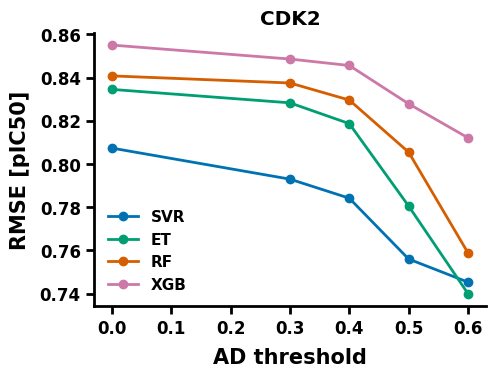

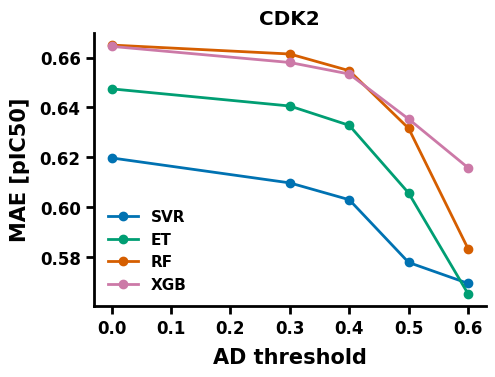

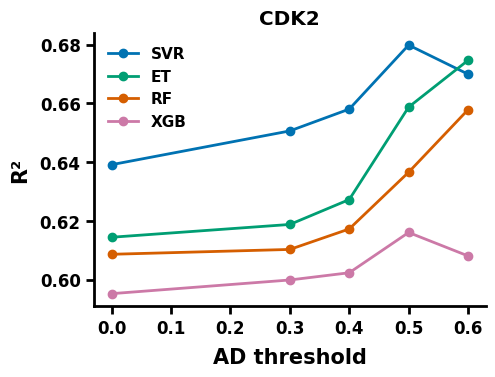

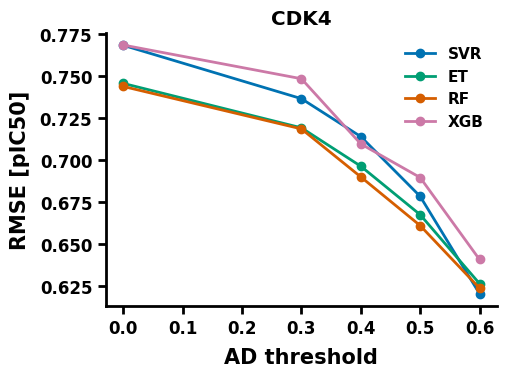

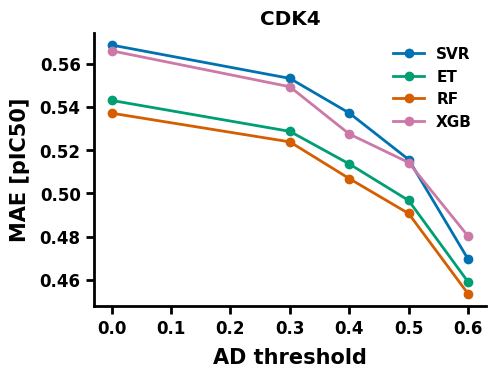

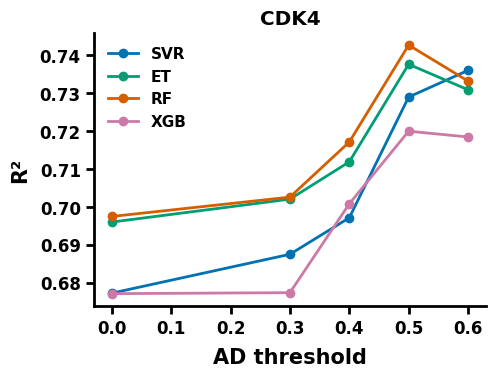

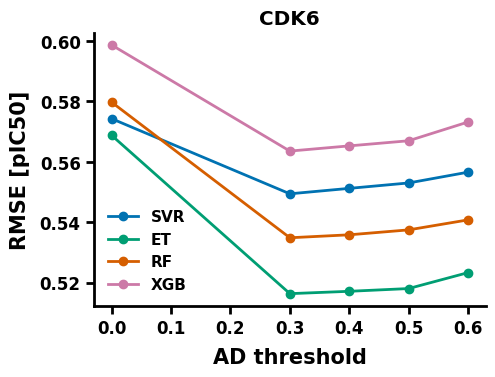

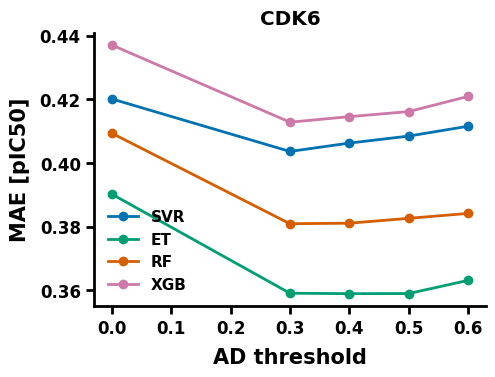

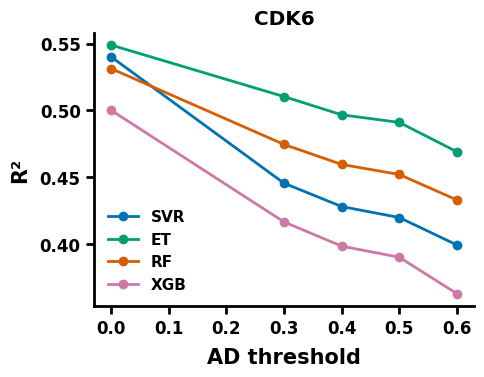

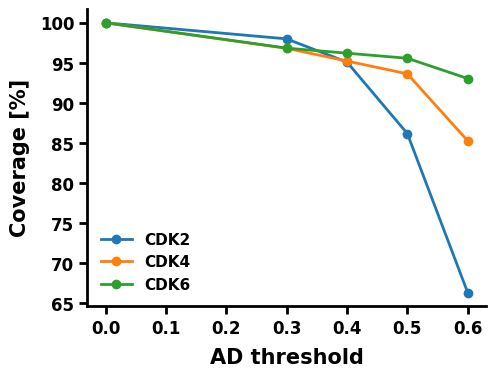

In [2]:
import matplotlib as mpl
mpl.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.labelsize':15,'axes.labelweight':'bold','xtick.labelsize':12,'ytick.labelsize':12,'axes.linewidth':2,'pdf.fonttype':42,'svg.fonttype':'none','savefig.facecolor':'white','figure.facecolor':'white','axes.facecolor':'white','axes.grid':False})
def figure():
    return plt.subplots(figsize=(130/25.4,100/25.4))
def finish(fig,ax,name,x,y,legend=False):
    ax.set(xlabel=x,ylabel=y); ax.xaxis.labelpad=7; ax.yaxis.labelpad=7
    for side in ['top','right']: ax.spines[side].set_visible(False)
    ax.tick_params(which='major',width=2,length=6,direction='out',labelsize=12); ax.minorticks_off(); ax.grid(False)
    for label in ax.get_xticklabels()+ax.get_yticklabels(): label.set_fontweight('bold')
    if legend: ax.legend(frameon=False,prop={'weight':'bold','size':11})
    fig.tight_layout()
    for ext in ['png','pdf','svg']: fig.savefig(OUT/f'{name}.{ext}',dpi=600)
    plt.show(); plt.close(fig)
models=['SVR','ET','RF','XGB']
targets=['CDK2','CDK4','CDK6']
colors=dict(zip(models,['#0072B2','#009E73','#D55E00','#CC79A7']))
for t in targets:
    for metric,label in [('RMSE','RMSE [pIC50]'),('MAE','MAE [pIC50]'),('R2','R²')]:
        fig,ax=figure()
        for m in models:
            g=audit[(audit.target==t)&(audit.model==m)]
            ax.plot(g.threshold,g[metric],marker='o',color=colors[m],label=m,linewidth=2)
        ax.set_title(t,fontweight='bold')
        finish(fig,ax,f'{t}_{metric}_all_models','AD threshold',label,True)
fig,ax=figure()
for t in targets:
    g=audit[(audit.target==t)&(audit.model=='SVR')]
    ax.plot(g.threshold,100*g.coverage,marker='o',label=t,linewidth=2)
finish(fig,ax,'coverage','AD threshold','Coverage [%]',True)


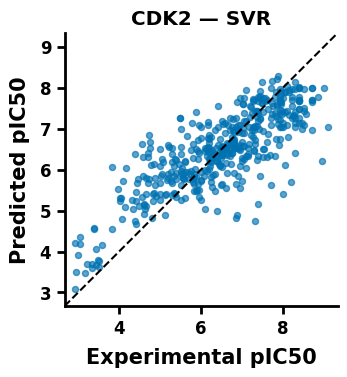

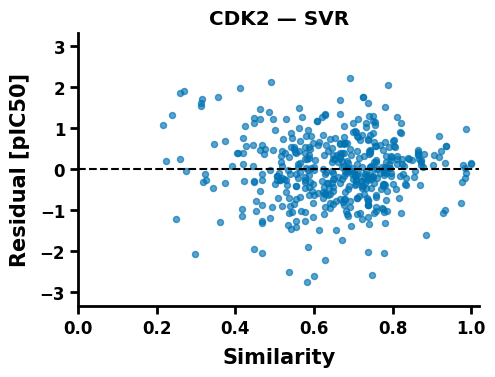

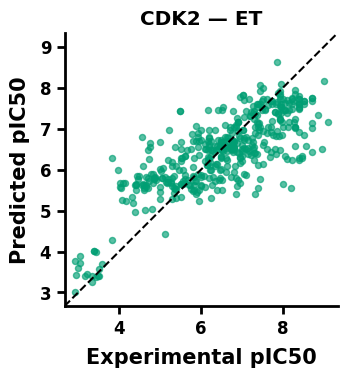

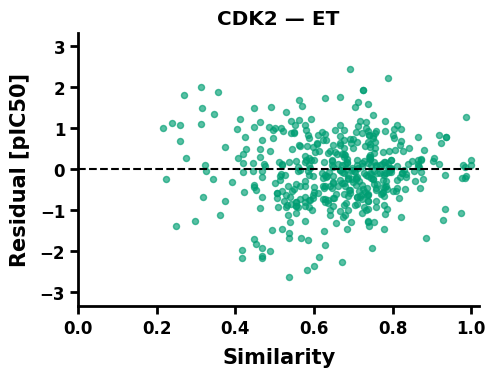

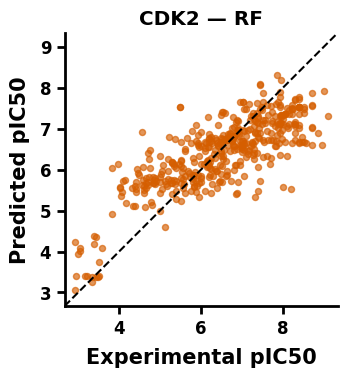

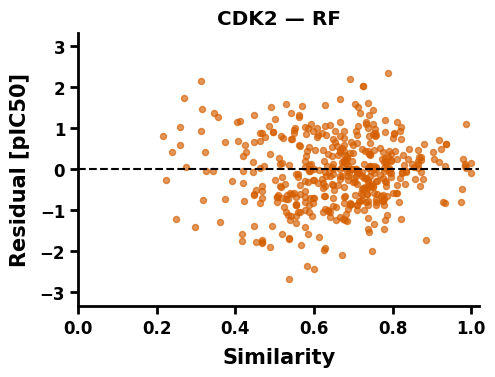

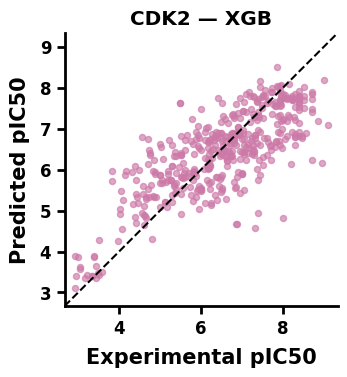

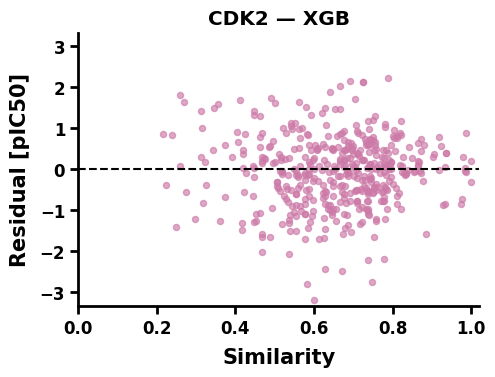

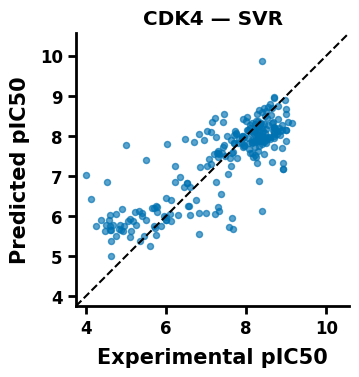

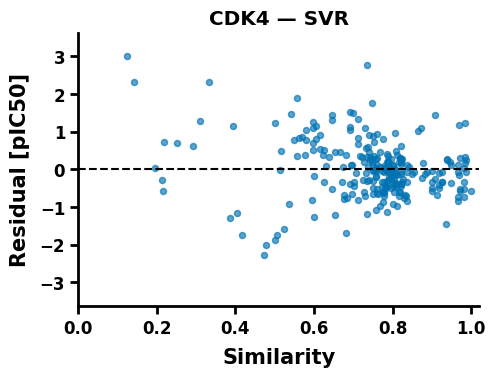

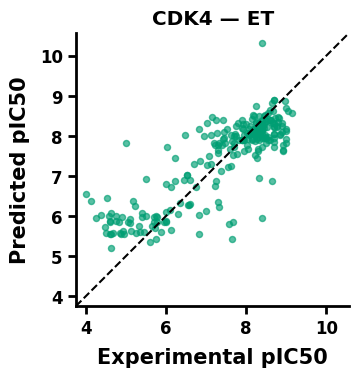

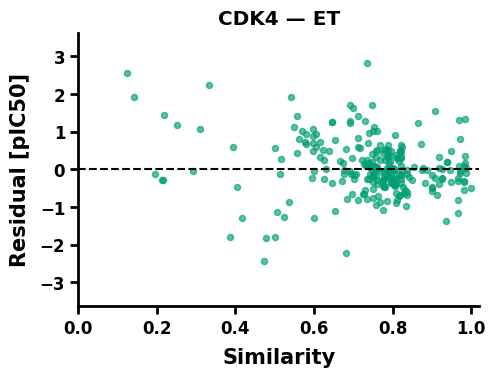

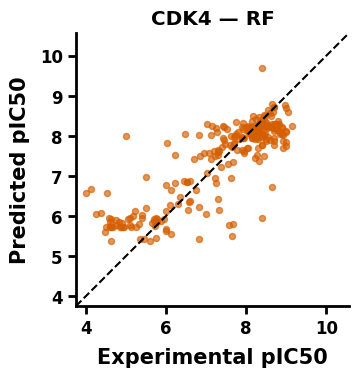

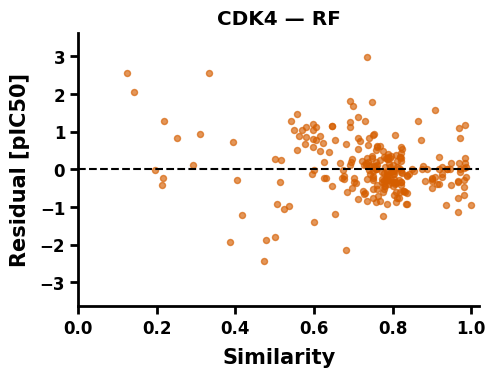

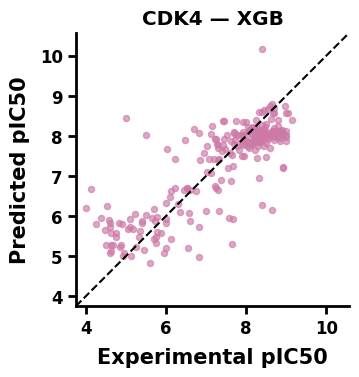

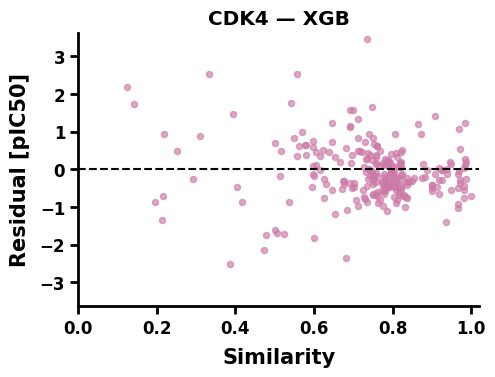

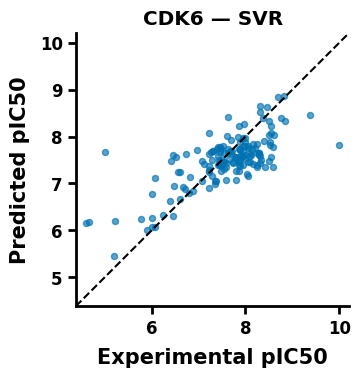

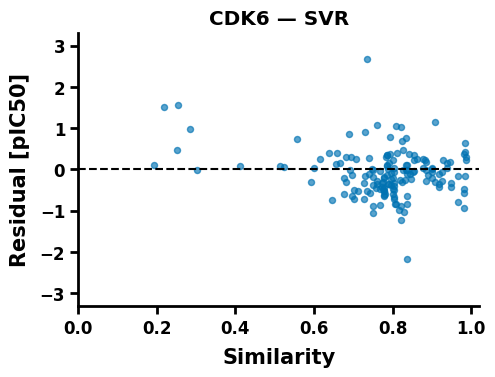

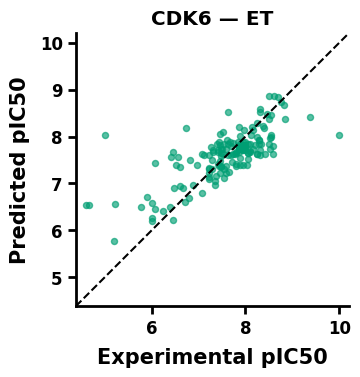

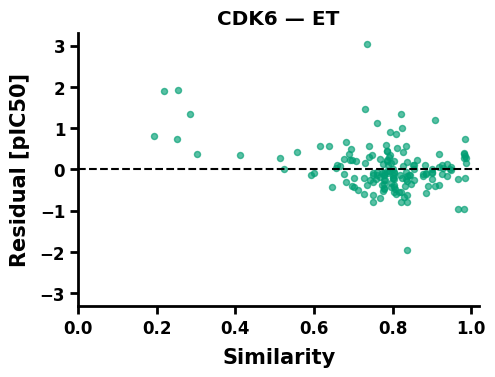

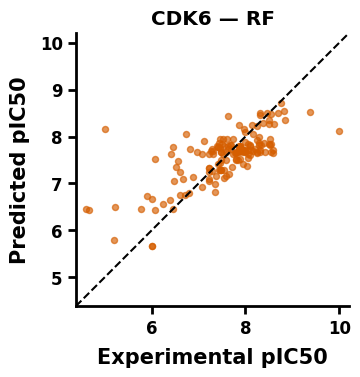

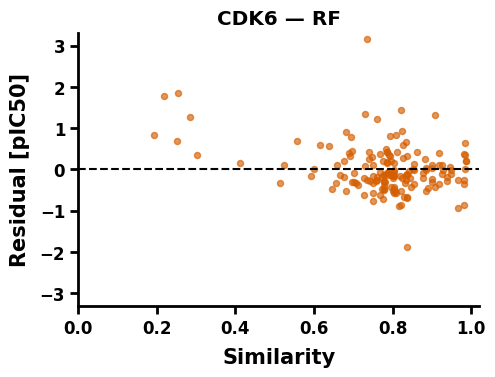

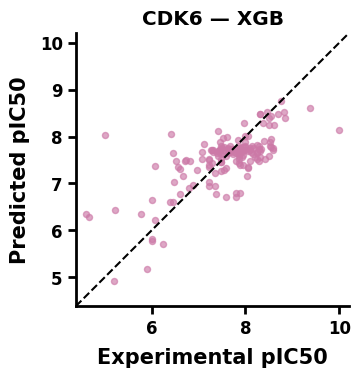

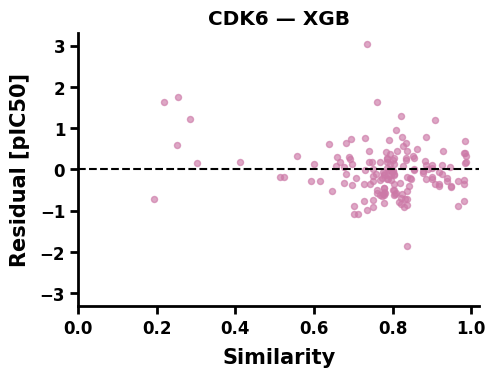

,threshold,n,RMSE,R2,activity_variance
40,0.0,158,0.56874,0.54885,0.71697
41,0.3,153,0.51634,0.51035,0.54449
42,0.4,152,0.51712,0.49676,0.53139
43,0.5,151,0.51803,0.49107,0.52729
44,0.6,147,0.52330,0.46917,0.51588


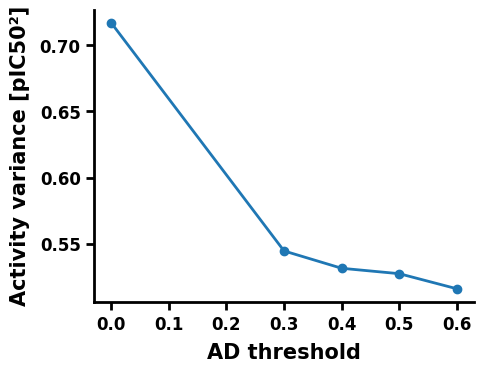

RMSE_improvement         MAE_improvement         R2_improvement        
                    min     max             min     max            min     max
target                                                                        
CDK2            -0.0174  0.0313         -0.0115  0.0285        -0.0154  0.0296
CDK4            -0.0015  0.0278         -0.0075  0.0027        -0.0012  0.0236
CDK6            -0.0263  0.0319         -0.0421  0.0293        -0.0461  0.0689

In [3]:
for t in targets:
    a=pred[pred.target==t]
    lo=min(a.pIC50.min(),a.predicted.min()); hi=max(a.pIC50.max(),a.predicted.max())
    pad=(hi-lo)*.04; lo-=pad; hi+=pad
    lim=max(abs(a.predicted-a.pIC50))*1.05
    for m in models:
        q=a[a.model==m]
        fig,ax=figure(); ax.scatter(q.pIC50,q.predicted,s=19,alpha=.65,color=colors[m]); ax.plot([lo,hi],[lo,hi],'k--',linewidth=1.5); ax.set(xlim=(lo,hi),ylim=(lo,hi),aspect='equal'); ax.set_title(f'{t} — {m}',fontweight='bold')
        finish(fig,ax,f'{t}_{m}_parity','Experimental pIC50','Predicted pIC50')
        fig,ax=figure(); ax.scatter(q.similarity,q.predicted-q.pIC50,s=19,alpha=.65,color=colors[m]); ax.axhline(0,color='black',linestyle='--'); ax.set(xlim=(0,1.02),ylim=(-lim,lim)); ax.set_title(f'{t} — {m}',fontweight='bold')
        finish(fig,ax,f'{t}_{m}_residual','Similarity','Residual [pIC50]')
q=audit[(audit.target=='CDK6')&(audit.model=='ET')]; display(q[['threshold','n','RMSE','R2','activity_variance']].round(5))
fig,ax=figure(); ax.plot(q.threshold,q.activity_variance,marker='o',linewidth=2); finish(fig,ax,'CDK6_variance','AD threshold','Activity variance [pIC50²]')
display(comp.groupby('target')[['RMSE_improvement','MAE_improvement','R2_improvement']].agg(['min','max']).round(4))


## Interpretation
R² depends on retained activity variance: R² = 1 − MSE / population variance. Changes in filtered R² cannot be interpreted as paired improvement on a fixed population. Baseline/optimized comparisons here use supplied aggregate paired records; uncertainty of their differences cannot be calculated without optimized individual predictions. The holdout should not be used to select a threshold and then advertised as independent validation. A common threshold of 0.4 is a descriptive candidate, not a final validated choice; calibrate on training-only out-of-fold predictions or a separate validation set. Natural-product coverage must be evaluated separately.